# Notebook 12: N-HiTS en PatchTST consumption huis
---
- N-HiTS en PatchTST op huis `consumption`, 3 dagen (864 stappen) vooruit
- Zelfde split en testvensters als GRU-consumption en notebook 11
- Runtime per model bijgehouden met `time`

### 1. Literatuur
---
**Probleem met de eerdere modellen.** LSTM, GRU, SARIMAX en LightGBM bleven op ~900 W MAE steken, terwijl simpele persistence ("zelfde tijd gisteren") in notebook 06 op de laatste 20% van de reeks 363 W haalde. Dat wijst op een **distribution shift**: het niveau van het verbruik in 2026 wijkt af van de trainingsperiode. Een model dat op het gemiddelde en de standaarddeviatie van de trainingsset is genormaliseerd, zit dan structureel naast de werkelijkheid.

**Reversible Instance Normalization (RevIN)** — Kim et al. (2022) laten zien dat het normaliseren van *elk invoervenster afzonderlijk* (en de voorspelling daarna weer terugschalen) de fout bij distribution shift sterk verlaagt, voor verschillende modeltypes. Beide modellen hieronder gebruiken deze vorm van per-venster-normalisatie (PatchTST via `revin=True`, N-HiTS via `scaler_type="robust"`).

**N-HiTS** (Challu et al., 2023) is een opvolger van N-BEATS (Oreshkin et al., 2020): een stapel MLP-blokken die elk op een andere tijdschaal werken. Met *multi-rate pooling* kijkt het eerste blok naar grove patronen (bijv. per 6 uur), het laatste naar fijne details (5 minuten); de voorspellingen worden met *hierarchical interpolation* samengevoegd. De auteurs rapporteren op lange-horizonbenchmarks (o.a. de Electricity-dataset met huishoudelijk verbruik) gemiddeld bijna 20% nauwkeuriger resultaten dan de toen beste Transformers, bij een veelvoud kortere rekentijd. Dat past bij onze horizon van 864 stappen.

**PatchTST** (Nie et al., 2023) is een Transformer die de reeks opknipt in *patches* (stukjes van bijv. 4 uur) en die als "woorden" behandelt. Patching verkort de invoer voor de attention sterk en laat het model lokale vormen (een ochtend- of avondpiek) als geheel zien. Het kwam na Zeng et al. (2023), dat aantoonde dat eerdere Transformers op lange horizons vaak verloren van een simpel lineair model; PatchTST versloeg die lineaire modellen wel, ook op Electricity.

**Waarom allebei?** In de benchmarks is er geen vaste winnaar tussen de twee: het verschil hangt af van de dataset en de horizon. N-HiTS is sneller en eenvoudiger, PatchTST is krachtiger maar zwaarder. Daarom worden ze hier op exact dezelfde testset vergeleken.

**Verwachting.** Verbruik van een individueel huishouden is erg grillig en daardoor moeilijk te voorspellen (Kong et al., 2019); korte pieken (waterkoker, oven) zijn op 3 dagen vooruit niet voorspelbaar. Een realistische winst zit vooral in het goed treffen van niveau en dagpatroon.

**Bronnen**
- Challu, C., Olivares, K. G., Oreshkin, B. N., Garza, F., Mergenthaler-Canseco, M., & Dubrawski, A. (2023). N-HiTS: Neural Hierarchical Interpolation for Time Series Forecasting. *Proceedings of the AAAI Conference on Artificial Intelligence, 37*(6), 6989–6997.
- Kim, T., Kim, J., Tae, Y., Park, C., Choi, J.-H., & Choo, J. (2022). Reversible Instance Normalization for Accurate Time-Series Forecasting against Distribution Shift. *International Conference on Learning Representations (ICLR)*.
- Kong, W., Dong, Z. Y., Jia, Y., Hill, D. J., Xu, Y., & Zhang, Y. (2019). Short-Term Residential Load Forecasting Based on LSTM Recurrent Neural Network. *IEEE Transactions on Smart Grid, 10*(1), 841–851.
- Nie, Y., Nguyen, N. H., Sinthong, P., & Kalagnanam, J. (2023). A Time Series is Worth 64 Words: Long-term Forecasting with Transformers. *International Conference on Learning Representations (ICLR)*.
- Oreshkin, B. N., Carpov, D., Chapados, N., & Bengio, Y. (2020). N-BEATS: Neural basis expansion analysis for interpretable time series forecasting. *International Conference on Learning Representations (ICLR)*.
- Zeng, A., Chen, M., Zhang, L., & Xu, Q. (2023). Are Transformers Effective for Time Series Forecasting? *Proceedings of the AAAI Conference on Artificial Intelligence, 37*(9), 11121–11128.

### 2. Inladen
---
- Libraries en paths
- Installatie (eenmalig): `pip install neuralforecast` (installeert ook PyTorch Lightning). Gebruikt automatisch de GPU als die er is.

In [ ]:

import sys
import time
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS, PatchTST
from neuralforecast.losses.pytorch import MAE

logging.getLogger("pytorch_lightning").setLevel(logging.WARNING)
torch.set_float32_matmul_precision("high")

start_notebook = time.perf_counter()
runtimes = {}
print("GPU:", torch.cuda.is_available())

# Projectmap zoeken
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
sys.path.insert(0, str(ROOT))

from exploration.open_meteo_weer_merge import haal_modeldata_op

split = pd.read_parquet(ROOT / "prepared_data" / "model_split.parquet").iloc[0]
df = haal_modeldata_op()

RESULTS_DIR = ROOT / "models" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


W1116 13:53:34.336000 13008 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


GPU: True
Data: C:\Users\casde\Desktop\Project3\Project3_Deel1\prepared_data\forecast_targets_with_weather.parquet


### 3. Voorspel instellingen
---

In [ ]:
stap_per_dag = 24 * 12

aantal_dagen_input = 7
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3
horizon = aantal_dagen_forecast * stap_per_dag

stride_test = 12

### 4. Data en split
---
- Zelfde filter en split als GRU-consumption

In [ ]:
t0 = time.perf_counter()

huis_cons = df[(df["location"] == "huis") & (df["target_type"] == "consumption")].copy()
huis_cons = huis_cons.dropna(subset=["pow_imputed"])
huis_cons = huis_cons.sort_values("timestamp_nl").reset_index(drop=True)

runtimes["data inladen"] = time.perf_counter() - t0

huis_cons = huis_cons[
    (huis_cons["timestamp_nl"] >= split["train_start"]) &
    (huis_cons["timestamp_nl"] < split["test_end"])
].reset_index(drop=True)

y_arr = huis_cons["pow_imputed"].to_numpy(np.float32)
n = len(y_arr)

tijd = pd.to_datetime(huis_cons["timestamp_nl"])
i_train = tijd.searchsorted(split["train_end"])
i_val = tijd.searchsorted(split["test_start"])

# Zelfde forecastmomenten als GRU-consumption en notebook 11
test_origins = i_val + input_len + np.arange(
    0, (n - i_val) - input_len - horizon + 1, stride_test
)

print(huis_cons.shape)
print(f"n = {n} | train t/m {i_train} | val t/m {i_val} | test t/m {n}")
print("Start test:", huis_cons["timestamp_nl"].iloc[i_val])
print(f"Aantal test-forecasts: {len(test_origins)}")


(48228, 16)
n = 48228 | train t/m 33240 | val t/m 40740 | test t/m 48228
Start test: 2026-03-18 11:00:00+01:00
Aantal test-forecasts: 385


### 5. Evaluatiefuncties
---
- Baselines, scores en plots

In [4]:
def baselines(origins):
    h = np.arange(horizon)
    t = origins[:, None] + h[None, :]
    k = h // stap_per_dag + 1
    dag = y_arr[t - stap_per_dag * k]
    week = y_arr[t - input_len]
    return dag, week


def echte_waarden(origins):
    return y_arr[origins[:, None] + np.arange(horizon)[None, :]]


def scores(pred, echt):
    fout = pred - echt
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for d in range(aantal_dagen_forecast):
        s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.abs(fout[:, s]).mean()
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride_test)
    res["rolling MAE"] = np.abs(fout[dagelijks]).mean(axis=1).mean()
    res["rolling RMSE"] = np.sqrt((fout[dagelijks] ** 2).mean(axis=1)).mean()
    return res


def plot_voorspelling(voorspellingen, idx=0, titel="Voorspelling vs. echt"):
    o = test_origins[idx]
    hist = y_arr[o - input_len:o]
    echt = y_arr[o:o + horizon]
    t_hist = np.arange(-input_len, 0) / stap_per_dag
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color="grey", label="Input (historie)")
    plt.plot(t_fc, echt, color="black", alpha=0.7, label="Echt")
    for naam, pred in voorspellingen.items():
        mae = np.abs(pred[idx] - echt).mean()
        plt.plot(t_fc, pred[idx], label=f"{naam} (MAE {mae:.0f} W)")
    plt.axvline(0, color="black", linestyle="--", alpha=0.5)
    plt.xlabel("Dagen t.o.v. start voorspelling")
    plt.ylabel("Verbruik (W)")
    plt.title(titel)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def plot_mae_per_stap(voorspellingen, echt):
    plt.figure(figsize=(10, 3.5))
    for naam, pred in voorspellingen.items():
        plt.plot(np.arange(horizon) / stap_per_dag, np.abs(pred - echt).mean(axis=0), label=naam)
    plt.xlabel("Dagen vooruit")
    plt.ylabel("MAE (W)")
    plt.title("MAE per voorspelstap")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

### 6. Data voor `neuralforecast`
---
- `neuralforecast` verwacht een tabel met `unique_id`, `ds` (tijd) en `y`.
- Als tijd wordt de **positie** (0, 1, 2, ...) gebruikt met `freq=1`. Dat sluit aan bij de GRU (die ook op positie werkt) en voorkomt problemen met zomer-/wintertijd.
- Getraind wordt op train + val, waarbij `val_size` de validatieperiode apart houdt voor early stopping. De testset wordt niet gezien.

In [5]:
train_val_df = pd.DataFrame({"unique_id": "huis", "ds": np.arange(i_val), "y": y_arr[:i_val]})
val_size = i_val - i_train
print(train_val_df.shape, "| val_size:", val_size)

(40740, 3) | val_size: 7500


### 7. Modellen
---
**N-HiTS**
- `n_freq_downsample=[72, 12, 1]`: de drie blokken voorspellen op resp. 6-uurs, uurs- en 5-minutenresolutie.
- `n_pool_kernel_size=[16, 4, 1]`: hoeveel de invoer per blok wordt samengevat (grof → fijn).

**PatchTST**
- `patch_len=48` (4 uur) met `stride=24` (2 uur overlap): 7 dagen historie worden 83 patches.
- `revin=True`: per-venster-normalisatie (Kim et al., 2022).

Beide: MAE-loss (zelfde als de L1-loss van de GRU), early stopping op de validatieset.

In [6]:
MAX_STEPS = 2000
PATIENCE = 5
VAL_CHECK = 100

nhits = NHITS(
    h=horizon,
    input_size=input_len,
    n_pool_kernel_size=[16, 4, 1],
    n_freq_downsample=[72, 12, 1],
    mlp_units=[[512, 512]] * 3,
    scaler_type="robust",  #per-venster-normalisatie
    loss=MAE(),
    learning_rate=1e-3,
    max_steps=MAX_STEPS,
    early_stop_patience_steps=PATIENCE,
    val_check_steps=VAL_CHECK,
    batch_size=32,
    windows_batch_size=256,
    random_seed=42,
    alias="N-HiTS",
)

patchtst = PatchTST(
    h=horizon,
    input_size=input_len,
    patch_len=48,
    stride=24,
    encoder_layers=3,
    n_heads=8,
    hidden_size=128,
    linear_hidden_size=256,
    dropout=0.2,
    revin=True,  #RevIN
    scaler_type="identity",
    loss=MAE(),
    learning_rate=1e-4,
    max_steps=MAX_STEPS,
    early_stop_patience_steps=PATIENCE,
    val_check_steps=VAL_CHECK,
    batch_size=32,
    windows_batch_size=128,  #lager bij geheugenproblemen op de GPU
    random_seed=42,
    alias="PatchTST",
)

MODELLEN = {"N-HiTS": nhits, "PatchTST": patchtst}

Seed set to 42
Seed set to 42


### 8. Trainen
---
- Elk model apart, zodat de runtime per model gemeten wordt

In [7]:
nf_modellen = {}
for naam, model in MODELLEN.items():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start_totaal = time.perf_counter()

    nf = NeuralForecast(models=[model], freq=1)
    nf.fit(df=train_val_df, val_size=val_size)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    runtimes[f"training {naam}"] = time.perf_counter() - start_totaal
    nf_modellen[naam] = nf
    print(f"{naam}: totale trainingstijd {runtimes[f'training {naam}']:.1f}s "
          f"({runtimes[f'training {naam}'] / 60:.1f} min)")

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Users\casde\Desktop\Project3\venv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\casde\Desktop\Project3\venv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (12 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

PatchTST: totale trainingstijd 23.4s (0.4 min)


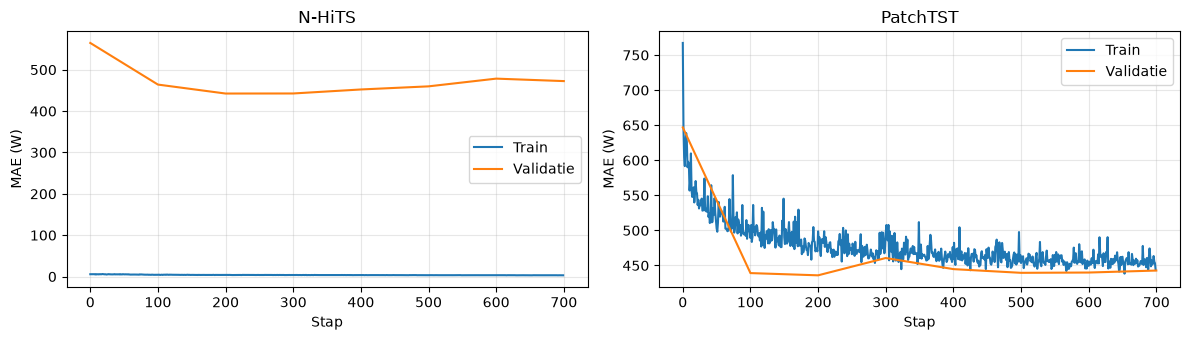

In [8]:
#Trainings- en validatieloss
fig, axes = plt.subplots(1, len(nf_modellen), figsize=(12, 3.5))
for ax, (naam, nf) in zip(np.atleast_1d(axes), nf_modellen.items()):
    m = nf.models[0]
    train_trajectory = getattr(m, "train_trajectories", [])
    valid_trajectory = getattr(m, "valid_trajectories", [])
    if train_trajectory:
        ax.plot(*zip(*train_trajectory), label="Train")
    if valid_trajectory:
        ax.plot(*zip(*valid_trajectory), label="Validatie")
    ax.set_title(naam)
    ax.set_xlabel("Stap")
    ax.set_ylabel("MAE (W)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 9. Voorspellen op de testset
---
- Elk testvenster (7 dagen historie) wordt als aparte reeks (`unique_id`) aangeboden; zo voorspelt het model alle 2600+ vensters in een paar batches.
- Het model gebruikt alleen de laatste `input_len` punten van elke reeks.

In [9]:
def voorspel_nf(nf, naam, origins, blok=500):
    preds = []
    for i in range(0, len(origins), blok):
        deel = origins[i:i + blok]
        ctx = np.stack([y_arr[o - input_len:o] for o in deel])
        ctx_df = pd.DataFrame({
            "unique_id": np.repeat(np.arange(len(deel)), input_len),
            "ds": np.tile(np.arange(input_len), len(deel)),
            "y": ctx.ravel(),
        })
        out = nf.predict(df=ctx_df)
        if "unique_id" not in out.columns:
            out = out.reset_index()
        out = out.sort_values(["unique_id", "ds"])
        preds.append(out[naam].to_numpy().reshape(len(deel), horizon))
    return np.vstack(preds)


echt_test = echte_waarden(test_origins)
voorspellingen = {}
for naam, nf in nf_modellen.items():
    t0 = time.perf_counter()
    voorspellingen[naam] = voorspel_nf(nf, naam, test_origins)
    runtimes[f"voorspellen {naam}"] = time.perf_counter() - t0
    print(f"{naam}: {len(test_origins)} forecasts in {runtimes[f'voorspellen {naam}']:.1f}s "
          f"({runtimes[f'voorspellen {naam}'] / len(test_origins) * 1000:.1f} ms per forecast)")

base_dag, base_week = baselines(test_origins)

c:\Users\casde\Desktop\Project3\venv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

N-HiTS: 385 forecasts in 0.3s (0.9 ms per forecast)


c:\Users\casde\Desktop\Project3\venv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

PatchTST: 385 forecasts in 0.3s (0.9 ms per forecast)


### 10. Resultaten
---

In [ ]:
alle = {**voorspellingen, "Persistence dag": base_dag, "Persistence week": base_week}
resultaten = pd.DataFrame({naam: scores(pred, echt_test) for naam, pred in alle.items()}).T
for naam in voorspellingen:
    resultaten.loc[naam, "trainingstijd (s)"] = runtimes[f"training {naam}"]
    resultaten.loc[naam, "voorspeltijd (s)"] = runtimes[f"voorspellen {naam}"]
resultaten = resultaten.round(1)
NOTEBOOK = "12_NHITS_PatchTST_huis_cons"

#Model opslaan en bestandsgrootte meten
MODEL_DIR = ROOT / "models" / "saved_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def grootte_mb(pad):
    pad = Path(pad)
    if pad.is_dir():
        return sum(f.stat().st_size for f in pad.rglob("*") if f.is_file()) / 1e6
    return pad.stat().st_size / 1e6

for naam, nf in nf_modellen.items():
    pad = MODEL_DIR / f"12_{naam.lower()}_huis_cons"
    nf.save(path=str(pad), overwrite=True, save_dataset=False)
    resultaten.loc[naam, "modelgrootte (MB)"] = grootte_mb(pad)
resultaten["modelgrootte (MB)"] = resultaten["modelgrootte (MB)"].round(3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
resultaten["notebook"] = NOTEBOOK
resultaten["locatie"] = "huis"
resultaten["target"] = "consumption"
resultaten["resolutie"] = "5 min"
resultaten["testperiode"] = (f"{huis_cons['timestamp_nl'].iloc[i_val]:%Y-%m-%d} t/m "
                             f"{huis_cons['timestamp_nl'].iloc[-1]:%Y-%m-%d}")
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / "12_nhits_patchtst_huis_cons.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
N-HiTS,12_NHITS_PatchTST_huis_cons,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,505.600006,738.799988,502.500000,494.500000,519.700012,495.500000,720.299988,13.3,0.3,29.241
PatchTST,12_NHITS_PatchTST_huis_cons,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,393.500000,644.599976,394.600006,393.399994,392.600006,434.700012,641.400024,23.4,0.3,38.837
Persistence dag,12_NHITS_PatchTST_huis_cons,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,305.000000,577.700012,295.000000,304.000000,316.100006,303.000000,568.000000,NaN,NaN,NaN
Persistence week,12_NHITS_PatchTST_huis_cons,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,292.700012,557.700012,291.399994,289.500000,297.299988,293.600006,552.900024,NaN,NaN,NaN


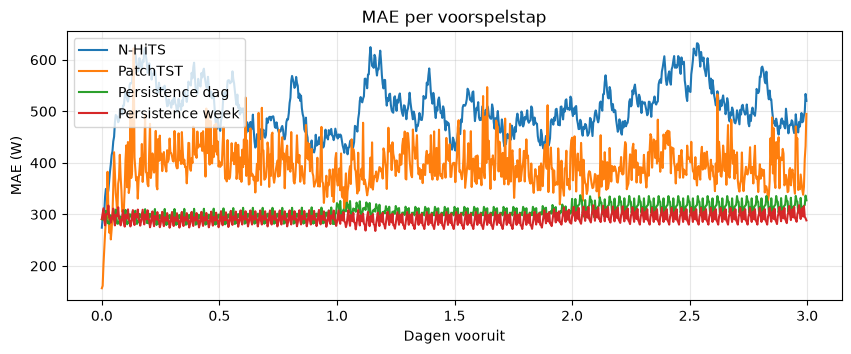

In [11]:
plot_mae_per_stap(alle, echt_test)

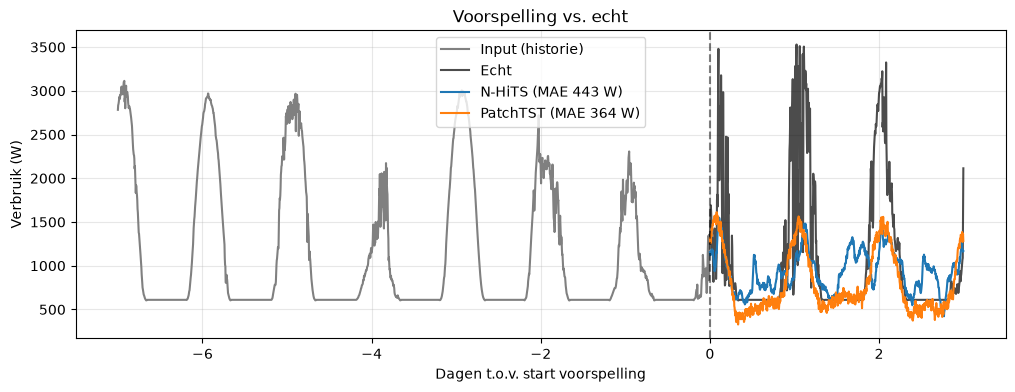

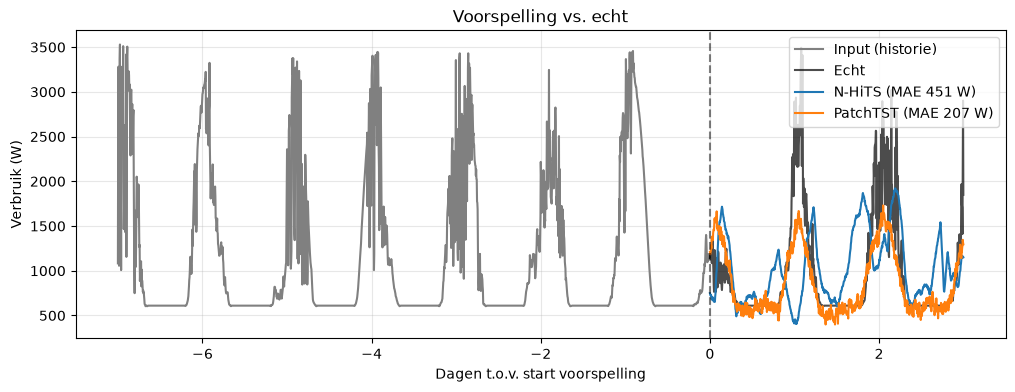

In [12]:
plot_voorspelling(voorspellingen, idx=0)
plot_voorspelling(voorspellingen, idx=len(test_origins) // 2)

### 11. Runtime overzicht
---

In [13]:
runtimes["totaal notebook"] = time.perf_counter() - start_notebook
runtime_df = pd.DataFrame({"seconden": runtimes}).assign(minuten=lambda d: d["seconden"] / 60).round(2)
runtime_df

,seconden,minuten
data inladen,0.13,0.00
training N-HiTS,13.32,0.22
training PatchTST,23.36,0.39
voorspellen N-HiTS,0.33,0.01
voorspellen PatchTST,0.33,0.01
totaal notebook,38.80,0.65
